# 02 — Merit order dispatch

**Does:** builds the merit order dispatch function, step by step.

**Input:** a toy 3-plant table first, then `data/raw/india_generator_stack.csv`

**Output:** a tested `merit_order_dispatch()` that will move to `src/dispatch.py`

**Method:** sort plants by marginal cost, dispatch the cheapest first until demand is met. The last plant running sets the clearing price. If demand can't be met, price = VOLL (scarcity price).

## Step 1: Toy example (3 plants)

Hand answers to check against:

| Demand | Dispatch | Price | Total cost |
|---|---|---|---|
| 30 MW | Solar 30 | 0 | 0 |
| 120 MW | Solar 40, Coal 80 | 2,000 | 160,000 |
| 200 MW | Solar 40, Coal 100, Gas 50, deficit 10 | VOLL | 425,000 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
plants = pd.DataFrame({
    "name": ["Gas", "Solar", "Coal"],
    "capacity_mw": [50, 40, 100],
    "cost": [4500, 0, 2000],
})
plants

,name,capacity_mw,cost
0,Gas,50,4500
1,Solar,40,0
2,Coal,100,2000


In [3]:
def merit_order_dispatch(demand, plants, voll=10000):
    # Arrange generators in increasing order of marginal cost
    plants = plants.sort_values("cost")

    remaining = demand
    total_cost = 0
    clearing_mc = None
    clearing_gen = None
    dispatch = {}

    for row in plants.itertuples():
        if remaining > row.capacity_mw:
            # Demand is bigger than this plant: run it at full capacity
            dispatch[row.name] = row.capacity_mw
            remaining -= row.capacity_mw
            total_cost += row.capacity_mw * row.cost
        else:
            # This plant covers what's left: it is the marginal plant
            dispatch[row.name] = remaining
            clearing_mc = row.cost
            clearing_gen = row.name
            total_cost += remaining * row.cost
            remaining = 0
            break

    surplus = plants["capacity_mw"].sum() - demand

    if remaining > 0:
        # Demand not met: scarcity price
        clearing_mc = voll
        clearing_gen = "Unserved"
        status = f"deficit of {remaining} MW"
    else:
        status = f"sufficient, surplus capacity {surplus} MW"

    return {
        "dispatch": dispatch,
        "clearing_gen": clearing_gen,
        "clearing_price": clearing_mc,
        "total_cost": total_cost,
        "status": status,
    }

In [4]:
for d in [30, 120, 200]:
    print(d, merit_order_dispatch(d, plants))

30 {'dispatch': {'Solar': 30}, 'clearing_gen': 'Solar', 'clearing_price': 0, 'total_cost': 0, 'status': 'sufficient, surplus capacity 160 MW'}
120 {'dispatch': {'Solar': 40, 'Coal': 80}, 'clearing_gen': 'Coal', 'clearing_price': 2000, 'total_cost': 160000, 'status': 'sufficient, surplus capacity 70 MW'}
200 {'dispatch': {'Solar': 40, 'Coal': 100, 'Gas': 50}, 'clearing_gen': 'Unserved', 'clearing_price': 10000, 'total_cost': 425000, 'status': 'deficit of 10 MW'}


## Step 2: Tests

The hand answers, plus boundary cases (demand exactly at a plant's limit). If anything breaks, an `assert` stops with an error.

In [5]:
expected = {
    # demand: (price, total cost)
    30:  (0, 0),
    120: (2000, 160000),
    200: (10000, 425000),   # deficit -> VOLL
    0:   (0, 0),            # no demand
    40:  (0, 0),            # solar exactly full
    140: (2000, 200000),    # coal exactly full
    190: (4500, 425000),    # every plant exactly full, no deficit
}
for d, (price, cost) in expected.items():
    r = merit_order_dispatch(d, plants)
    assert r["clearing_price"] == price, f"{d} MW: price {r['clearing_price']}, expected {price}"
    assert r["total_cost"] == cost, f"{d} MW: cost {r['total_cost']}, expected {cost}"
print("All tests pass")

All tests pass


## Step 3 (your exercise): add a 4th plant

Add **Nuclear, 30 MW, Rs 3,500/MWh**. Before running, predict by hand what happens at 200 MW:
- Does the deficit disappear?
- What is the new clearing price, and which plant sets it?

Write your prediction here, then run the code and compare.

In [6]:
plants4 = pd.concat([plants, pd.DataFrame({
    "name": ["Nuclear"], "capacity_mw": [30], "cost": [3500]
})], ignore_index=True)

merit_order_dispatch(200, plants4)

{'dispatch': {'Solar': 40, 'Coal': 100, 'Nuclear': 30, 'Gas': 30},
 'clearing_gen': 'Gas',
 'clearing_price': 4500,
 'total_cost': 440000,
 'status': 'sufficient, surplus capacity 20 MW'}

In [7]:
gen = pd.read_csv("../data/raw/india_generator_stack.csv")

# National stack: total capacity per fuel, cheapest first
stack = (gen.groupby(["Fuel_Type", "Marginal_Cost_Rs_per_MWh"], as_index=False)["Capacity_MW"]
            .sum()
            .sort_values("Marginal_Cost_Rs_per_MWh"))
stack["Cum_MW"] = stack["Capacity_MW"].cumsum()
stack

,Fuel_Type,Marginal_Cost_Rs_per_MWh,Capacity_MW,Cum_MW
8,Solar,0.0,164234.50,164234.50
9,Wind,0.0,58136.89,222371.39
4,Large Hydro,1000.0,51854.66,274226.05
7,Small Hydro,1000.0,5172.46,279398.51
1,Coal,2000.0,216327.51,495726.02
5,Lignite,2300.0,6620.00,502346.02
0,Biopower,3500.0,11727.43,514073.45
6,Nuclear,3500.0,8780.00,522853.45
3,Gas,4500.0,20122.42,542975.87
2,Diesel,11000.0,469.66,543445.53


In [8]:
demand = pd.read_csv("../data/processed/india_electricity_data_updated.csv")
national = demand.groupby("Date")["Max Demand Met"].sum()
national.describe()

count      1917.000000
mean     198310.308816
std       23624.279309
min      126618.000000
25%      180324.000000
50%      199382.000000
75%      216201.000000
max      255116.000000
Name: Max Demand Met, dtype: float64

In [9]:
demand[demand["Energy Shortage"] < 0][["Date", "State", "Energy Shortage"]].count()

Date               24
State              24
Energy Shortage    24
dtype: int64

In [10]:
demand[demand["Energy Shortage"] < 0]

,Date,State,Max Demand Met,Shortage During Peak,Energy Met,Drawl Schedule,OD(+) / UD(-),Max OD,Energy Shortage
12801,2023-07-23 00:00:00,DD & DNH,1237.0,1289.0,0.0,-769.0,-704.0,-746.0,-17.91
13070,2024-04-17 00:00:00,DD & DNH,1237.0,1259.0,0.0,-1415.0,-908.0,-1065.0,-25.56
13393,2025-03-06 00:00:00,DD & DNH,1237.0,1326.0,0.0,-1219.0,-804.0,-892.0,-21.41
23063,2020-02-29 00:00:00,HP,1631.0,0.0,0.0,607.0,0.0,10.1,-10.10
23197,2020-07-12 00:00:00,HP,1479.0,0.0,0.0,333.0,0.0,4.7,-4.70
23204,2020-07-19 00:00:00,HP,1413.0,0.0,0.0,326.0,0.0,5.0,-5.00
23231,2020-08-15 00:00:00,HP,1367.0,0.0,83.0,-439.0,0.0,-15.5,-15.50
23232,2020-08-16 00:00:00,HP,1367.0,0.0,83.0,-439.0,0.0,-15.5,-15.50
23234,2020-08-18 00:00:00,HP,1198.0,0.0,0.0,-738.0,0.0,-16.5,-16.50
23651,2021-10-09 00:00:00,HP,1548.0,2.0,0.0,218.0,0.0,2.3,-2.30


In [11]:
availability = {
    "Solar": 0.25, "Wind": 0.30, "Large Hydro": 0.45, "Small Hydro": 0.40,
    "Coal": 0.75, "Lignite": 0.70, "Nuclear": 0.80, "Biopower": 0.50,
    "Gas": 0.30, "Diesel": 0.90,
}

stack["Available_MW"] = stack["Capacity_MW"] * stack["Fuel_Type"].map(availability)
stack["Cum_Available_MW"] = stack["Available_MW"].cumsum()
stack

,Fuel_Type,Marginal_Cost_Rs_per_MWh,Capacity_MW,Cum_MW,Available_MW,Cum_Available_MW
8,Solar,0.0,164234.50,164234.50,41058.6250,41058.6250
9,Wind,0.0,58136.89,222371.39,17441.0670,58499.6920
4,Large Hydro,1000.0,51854.66,274226.05,23334.5970,81834.2890
7,Small Hydro,1000.0,5172.46,279398.51,2068.9840,83903.2730
1,Coal,2000.0,216327.51,495726.02,162245.6325,246148.9055
5,Lignite,2300.0,6620.00,502346.02,4634.0000,250782.9055
0,Biopower,3500.0,11727.43,514073.45,5863.7150,256646.6205
6,Nuclear,3500.0,8780.00,522853.45,7024.0000,263670.6205
3,Gas,4500.0,20122.42,542975.87,6036.7260,269707.3465
2,Diesel,11000.0,469.66,543445.53,422.6940,270130.0405


In [12]:
real_plants = stack.rename(columns={
    "Fuel_Type": "name",
    "Available_MW": "capacity_mw",
    "Marginal_Cost_Rs_per_MWh": "cost",
})[["name", "capacity_mw", "cost"]]
real_plants

,name,capacity_mw,cost
8,Solar,41058.6250,0.0
9,Wind,17441.0670,0.0
4,Large Hydro,23334.5970,1000.0
7,Small Hydro,2068.9840,1000.0
1,Coal,162245.6325,2000.0
5,Lignite,4634.0000,2300.0
0,Biopower,5863.7150,3500.0
6,Nuclear,7024.0000,3500.0
3,Gas,6036.7260,4500.0
2,Diesel,422.6940,11000.0


In [13]:
demand[demand['State']=="DD & DNH"]

,Date,State,Max Demand Met,Shortage During Peak,Energy Met,Drawl Schedule,OD(+) / UD(-),Max OD,Energy Shortage
11502,2020-01-01 00:00:00,DD & DNH,1080.0,0.0,25.1,24.7,0.4,76.0,0.0
11503,2020-01-02 00:00:00,DD & DNH,991.0,0.0,22.5,22.4,0.1,58.0,0.0
11504,2020-01-03 00:00:00,DD & DNH,1097.0,0.0,24.0,23.8,0.2,74.0,0.0
11505,2020-01-04 00:00:00,DD & DNH,1112.0,0.0,25.8,25.4,0.4,71.0,0.0
11506,2020-01-05 00:00:00,DD & DNH,1103.0,0.0,25.5,25.1,0.4,80.0,0.0
...,...,...,...,...,...,...,...,...,...
13414,2025-03-27 00:00:00,DD & DNH,1237.0,1345.0,0.0,31.4,31.7,-0.3,50.0
13415,2025-03-28 00:00:00,DD & DNH,1237.0,1310.0,0.0,30.5,30.9,-0.4,41.0
13416,2025-03-29 00:00:00,DD & DNH,1237.0,1326.0,0.0,30.6,30.6,0.0,40.0
13417,2025-03-30 00:00:00,DD & DNH,1237.0,1271.0,0.0,29.2,29.3,-0.1,35.0


In [14]:
raw = pd.read_csv("../data/raw/india_electricity_data.csv")

shifted = raw["Max Demand Met"].isna() & raw["Shortage During Peak"].notna()
print(shifted.sum())   # 1034

1034


In [15]:
shifted = raw["Max Demand Met"].isna() & raw["Shortage During Peak"].notna()
print(shifted.sum())   # should be 1034

1034


In [16]:
numeric_cols = ["Max Demand Met", "Shortage During Peak", "Energy Met",
                "Drawl Schedule", "OD(+) / UD(-)", "Max OD", "Energy Shortage"]

raw.loc[shifted, numeric_cols] = raw.loc[shifted, numeric_cols].shift(-1, axis=1)

In [17]:
# check: don't overwrite `shifted`
print((raw["Max Demand Met"].isna() & raw["Shortage During Peak"].notna()).sum())   # 0

0


In [18]:
# Energy Shortage was cut off for shifted rows; DNH's shortage is 0 on 96% of days
raw.loc[shifted, "Energy Shortage"] = 0


In [19]:
# Impossible values: mark as missing so the ffill step handles them
raw.loc[raw["Energy Met"] == 0, "Energy Met"] = np.nan
raw.loc[raw["Energy Shortage"] < 0, "Energy Shortage"] = np.nan

In [20]:
print((raw["Energy Met"] == 0).sum())                                          # 0
print((raw["Energy Shortage"] < 0).sum())                                      # 0
print((raw["Max Demand Met"].isna() & raw["Shortage During Peak"].notna()).sum())  # 0

0
0
0


In [21]:
peak_day = national.idxmax()
peak_mw = national.max()
print(peak_day, peak_mw)

merit_order_dispatch(peak_mw, real_plants)

2024-05-30 00:00:00 255116.0


{'dispatch': {'Solar': 41058.625,
  'Wind': 17441.067,
  'Large Hydro': 23334.597,
  'Small Hydro': 2068.984,
  'Coal': 162245.6325,
  'Lignite': 4634.0,
  'Biopower': np.float64(4333.094499999977)},
 'clearing_gen': 'Biopower',
 'clearing_price': 3500.0,
 'total_cost': np.float64(375718876.74999994),
 'status': 'sufficient, surplus capacity 15014.040500000061 MW'}

In [22]:
merit_order_dispatch(national.median(), real_plants)

{'dispatch': {'Solar': 41058.625,
  'Wind': 17441.067,
  'Large Hydro': 23334.597,
  'Small Hydro': 2068.984,
  'Coal': np.float64(115478.72699999998)},
 'clearing_gen': 'Coal',
 'clearing_price': 2000.0,
 'total_cost': np.float64(256361034.99999997),
 'status': 'sufficient, surplus capacity 70748.04050000006 MW'}

Finding national all day

In [23]:
results = []
for date, mw in national.items():
    r = merit_order_dispatch(mw, real_plants)
    results.append({
        "Date": date,
        "Demand_MW": mw,
        "Price": r["clearing_price"],
        "Marginal": r["clearing_gen"],
        "Cost": r["total_cost"],
    })

daily = pd.DataFrame(results)
daily["Date"] = pd.to_datetime(daily["Date"])
daily.head()

,Date,Demand_MW,Price,Marginal,Cost
0,2020-01-01,181721.0,2000.0,Coal,221039035.0
1,2020-01-02,176762.0,2000.0,Coal,211121035.0
2,2020-01-03,177961.0,2000.0,Coal,213519035.0
3,2020-01-04,178455.0,2000.0,Coal,214507035.0
4,2020-01-05,176908.0,2000.0,Coal,211413035.0


In [24]:
# How often does each fuel set the price?
daily["Marginal"].value_counts()

Marginal
Coal        1910
Lignite        4
Biopower       3
Name: count, dtype: int64

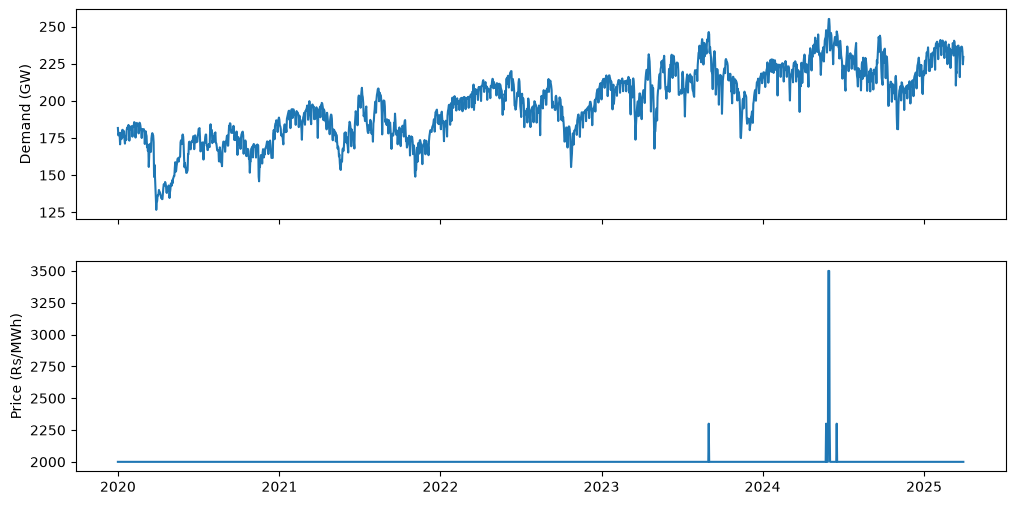

In [25]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(daily["Date"], daily["Demand_MW"] / 1000)
ax[0].set_ylabel("Demand (GW)")
ax[1].plot(daily["Date"], daily["Price"])
ax[1].set_ylabel("Price (Rs/MWh)")
plt.show()

State wise dispatch analysis for a single day 

In [26]:
# Fix the name mismatch first (found in the data audit)
gen["State"] = gen["State"].replace({"DNH and DD": "DD & DNH"})

# Step 2: demand per state on the chosen day
day = "2024-05-30"
day_demand = demand[demand["Date"].str.startswith(day)].set_index("State")["Max Demand Met"]

# Step 3: available generation per state
gen["Available_MW"] = gen["Capacity_MW"] * gen["Fuel_Type"].map(availability)
supply = gen.groupby("State")["Available_MW"].sum()

# Step 4: surplus / deficit
profile = pd.DataFrame({"Demand_MW": day_demand, "Available_MW": supply})
profile["Surplus_MW"] = profile["Available_MW"] - profile["Demand_MW"]
profile.sort_values("Surplus_MW")

,Demand_MW,Available_MW,Surplus_MW
State,,,
Punjab,13905.0,5515.8675,-8389.1325
Delhi,8017.0,788.0300,-7228.9700
Haryana,12164.0,5035.9320,-7128.0680
Kerala,3969.0,1945.4945,-2023.5055
NR UP,28584.0,26738.2045,-1845.7955
DD & DNH,1237.0,37.7250,-1199.2750
J&K(UT) & Ladakh(UT),2708.0,1695.5055,-1012.4945
Goa,797.0,24.9175,-772.0825
Assam,1611.0,1099.1245,-511.8755


In [27]:
profile["Surplus_MW"].sum()

np.float64(18578.040500000003)

In [28]:
results = []

for state, mw in day_demand.items():
    # This state's generators, renamed to fit your function
    plants_s = gen[gen["State"] == state].rename(columns={
        "Fuel_Type": "name",
        "Available_MW": "capacity_mw",
        "Marginal_Cost_Rs_per_MWh": "cost",
    })[["name", "capacity_mw", "cost"]]

    # Some states have demand but no generator data (DVC)
    if plants_s.empty:
        results.append({"State": state, "Marginal": "No generator data"})
        continue

    r = merit_order_dispatch(mw, plants_s)
    results.append({
        "State": state,
        "Demand_MW": mw,
        "Marginal": r["clearing_gen"],
        "Price": r["clearing_price"],
    })

marginal = pd.DataFrame(results).sort_values("Price")
marginal

,State,Demand_MW,Marginal,Price
1,Arunachal Pradesh,138.0,Large Hydro,1000.0
26,Sikkim,86.0,Large Hydro,1000.0
12,HP,1818.0,Large Hydro,1000.0
0,Andhra Pradesh,13231.0,Coal,2000.0
28,Telangana,11041.0,Coal,2000.0
25,SR Karnataka,13099.0,Coal,2000.0
24,Rajasthan,17460.0,Coal,2000.0
11,Gujarat,24208.0,Coal,2000.0
16,MP,14309.0,Coal,2000.0
3,Bihar,7298.0,Coal,2000.0


In [29]:
marginal["Marginal"].value_counts()

Marginal
Unserved             16
Coal                  9
Large Hydro           3
Gas                   2
Lignite               1
Biopower              1
No generator data     1
Name: count, dtype: int64

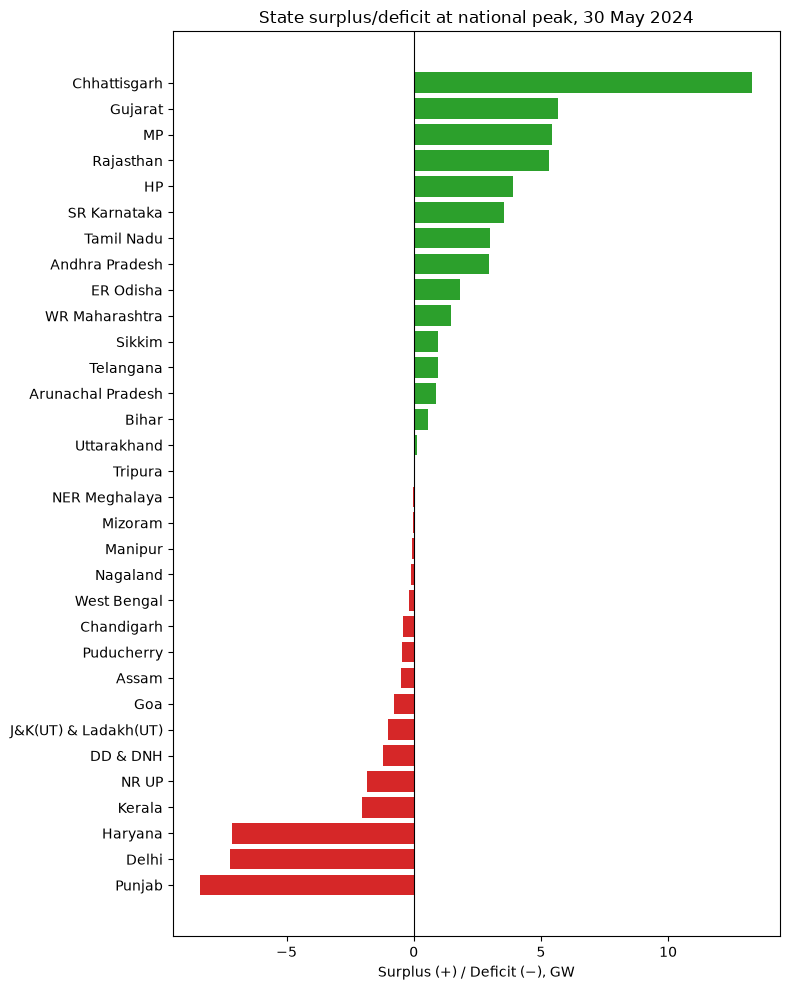

In [30]:
p = profile.dropna().sort_values("Surplus_MW")
colors = ["tab:red" if v < 0 else "tab:green" for v in p["Surplus_MW"]]

plt.figure(figsize=(8, 10))
plt.barh(p.index, p["Surplus_MW"] / 1000, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Surplus (+) / Deficit (−), GW")
plt.title("State surplus/deficit at national peak, 30 May 2024")
plt.tight_layout()
plt.show()

In [31]:
region = {
    "North": ["Punjab", "Haryana", "Delhi", "NR UP", "Rajasthan", "HP",
              "J&K(UT) & Ladakh(UT)", "Chandigarh", "Uttarakhand"],
    "West":  ["Gujarat", "MP", "Chhattisgarh", "WR Maharashtra", "Goa", "DD & DNH"],
    "South": ["Andhra Pradesh", "Telangana", "SR Karnataka", "Tamil Nadu", "Kerala", "Puducherry"],
    "East":  ["Bihar", "ER Odisha", "West Bengal", "Sikkim"],
    "NorthEast": ["Assam", "Arunachal Pradesh", "Manipur", "NER Meghalaya",
                  "Mizoram", "Nagaland", "Tripura"],
}

regional_results = []

for reg, states in region.items():
    # 1. This region's generators, combined by fuel (like the national stack)
    plants_r = (gen[gen["State"].isin(states)]
                .groupby(["Fuel_Type", "Marginal_Cost_Rs_per_MWh"], as_index=False)["Available_MW"]
                .sum()
                .rename(columns={
                    "Fuel_Type": "name",
                    "Available_MW": "capacity_mw",
                    "Marginal_Cost_Rs_per_MWh": "cost",
                }))

    # 2. This region's demand: add up its states
    demand_r = day_demand[day_demand.index.isin(states)].sum()

    # 3. Dispatch the region on its own
    r = merit_order_dispatch(demand_r, plants_r)

    # 4. Record the result
    served = sum(r["dispatch"].values())
    regional_results.append({
        "Region": reg,
        "Demand_MW": demand_r,
        "Available_MW": plants_r["capacity_mw"].sum(),
        "Unserved_MW": max(demand_r - served, 0),
        "Marginal": r["clearing_gen"],
        "Price": r["clearing_price"],
        "Cost_Rs_per_h": r["total_cost"],
    })

regional = pd.DataFrame(regional_results)
regional

,Region,Demand_MW,Available_MW,Unserved_MW,Marginal,Price,Cost_Rs_per_h
0,North,87814.0,71141.7895,1.667221e+04,Unserved,10000.0,1.100702e+08
1,West,74083.0,98002.7990,0.000000e+00,Coal,2000.0,9.705394e+07
2,South,61151.0,69136.2855,7.275958e-12,Lignite,2300.0,7.912351e+07
3,East,25877.0,29037.0810,0.000000e+00,Coal,2000.0,4.800960e+07
4,NorthEast,2627.0,2812.0855,0.000000e+00,Gas,4500.0,4.216811e+06


In [32]:
all_assigned = [s for states in region.values() for s in states]
missing = set(day_demand.index) - set(all_assigned)
print("Not in any region:", missing)   # should be only {'DVC'}

Not in any region: {'DVC'}


In [33]:
VOLL = 10000
iso_unserved = (marginal["Marginal"] == "Unserved").sum()

print("Regional: unserved", regional["Unserved_MW"].sum().round(0), "MW,",
      "cost incl. VOLL Rs", ((regional["Cost_Rs_per_h"].sum()
                              + regional["Unserved_MW"].sum() * VOLL) / 1e7).round(1), "crore/h")
print("States short in the isolated model:", iso_unserved)

Regional: unserved 16672.0 MW, cost incl. VOLL Rs 50.5 crore/h
States short in the isolated model: 16


In [34]:
import sys; print(sys.executable)

/Users/teja/Documents/strategic-grid-dispatch/.venv/bin/python


In [35]:
from scipy.optimize import linprog

def lp_dispatch(demand, plants, voll=10000):
    """
    Economic dispatch as a linear program.

    Variables : g_i = MW from each plant, u = unserved MW
    Objective : minimise  sum(cost_i * g_i) + voll * u
    Subject to: sum(g_i) + u = demand          (balance)
                0 <= g_i <= capacity_i         (plant limits)
                u >= 0
    """
    n = len(plants)

    # Objective coefficients: each plant's cost, then VOLL for unserved
    c = list(plants["cost"]) + [voll]

    # Balance constraint: one row, a 1 for every variable
    A_eq = [[1] * (n + 1)]
    b_eq = [demand]

    # Bounds: each plant 0..capacity, unserved 0..no limit
    bounds = [(0, cap) for cap in plants["capacity_mw"]] + [(0, None)]

    res = linprog(c=c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    if not res.success:
        raise RuntimeError(f"LP failed: {res.message}")

    g = res.x[:n]           # MW per plant
    u = res.x[n]            # unserved MW

    return {
        "dispatch": dict(zip(plants["name"], g)),
        "unserved_mw": u,
        "clearing_price": res.eqlin.marginals[0],      # shadow price of the balance constraint
        "fuel_cost": float(np.dot(plants["cost"], g)),
        "total_cost_incl_voll": res.fun,
    }

In [36]:
lp_dispatch(120, plants)

{'dispatch': {'Gas': np.float64(0.0),
  'Solar': np.float64(40.0),
  'Coal': np.float64(80.0)},
 'unserved_mw': np.float64(0.0),
 'clearing_price': np.float64(2000.0),
 'fuel_cost': 160000.0,
 'total_cost_incl_voll': 160000.0}

In [37]:
for d in [0, 30, 40, 120, 140, 190, 200]:
    lp = lp_dispatch(d, plants)
    mo = merit_order_dispatch(d, plants)
    print(d, "LP price:", lp["clearing_price"], " MO price:", mo["clearing_price"],
          " LP cost:", lp["fuel_cost"], " MO cost:", mo["total_cost"])

0 LP price: -0.0  MO price: 0  LP cost: 0.0  MO cost: 0
30 LP price: -0.0  MO price: 0  LP cost: 0.0  MO cost: 0
40 LP price: -0.0  MO price: 0  LP cost: 0.0  MO cost: 0
120 LP price: 2000.0  MO price: 2000  LP cost: 160000.0  MO cost: 160000
140 LP price: 2000.0  MO price: 2000  LP cost: 200000.0  MO cost: 200000
190 LP price: 10000.0  MO price: 4500  LP cost: 425000.0  MO cost: 425000
200 LP price: 10000.0  MO price: 10000  LP cost: 425000.0  MO cost: 425000


In [38]:
plants

,name,capacity_mw,cost
0,Gas,50,4500
1,Solar,40,0
2,Coal,100,2000


In [39]:
lp_prices = pd.Series({d: lp_dispatch(mw, real_plants)["clearing_price"] for d, mw in national.items()})
mo_prices = pd.Series({d: merit_order_dispatch(mw, real_plants)["clearing_price"] for d, mw in national.items()})

print("Days where prices disagree:", (lp_prices != mo_prices).sum())

Days where prices disagree: 0


In [40]:
def region_plants(states):
    """A region's generators, grouped by fuel, in the format the LP expects."""
    return (gen[gen["State"].isin(states)]
            .groupby(["Fuel_Type", "Marginal_Cost_Rs_per_MWh"], as_index=False)["Available_MW"].sum()
            .rename(columns={"Fuel_Type": "name", "Available_MW": "capacity_mw",
                             "Marginal_Cost_Rs_per_MWh": "cost"}))


def lp_two_region(d_N, p_N, d_W, p_W, line_limit, voll=10000):
    """
    Two-region dispatch with one transmission line West -> North.

    Variables (in this order):
        g_N : MW from each North plant          (nN of them)
        u_N : North unserved MW
        g_W : MW from each West plant           (nW of them)
        u_W : West unserved MW
        f   : flow on the line, West -> North   (negative = North -> West)

    Objective : minimise  cost of all plants + VOLL * (u_N + u_W)     (the line itself costs nothing)
    Subject to:
        North balance:  sum(g_N) + u_N + f = d_N     (imports help the North)
        West balance:   sum(g_W) + u_W - f = d_W     (exports are extra demand for the West)
        0 <= g <= capacity,  u >= 0,  -line_limit <= f <= line_limit
    """
    nN, nW = len(p_N), len(p_W)

    # Objective: [North plants, u_N, West plants, u_W, f]
    c = list(p_N["cost"]) + [voll] + list(p_W["cost"]) + [voll] + [0]

    # Two balance rows, one per region
    north_row = [1] * nN + [1] + [0] * nW + [0] + [ 1]
    west_row  = [0] * nN + [0] + [1] * nW + [1] + [-1]
    A_eq = [north_row, west_row]
    b_eq = [d_N, d_W]

    bounds = ([(0, cap) for cap in p_N["capacity_mw"]] + [(0, None)] +
              [(0, cap) for cap in p_W["capacity_mw"]] + [(0, None)] +
              [(-line_limit, line_limit)])

    res = linprog(c=c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    if not res.success:
        raise RuntimeError(f"LP failed: {res.message}")

    x = res.x
    price_N, price_W = res.eqlin.marginals          # one shadow price per balance row
    flow = x[-1]
    return {
        "Line_MW": line_limit,
        "Flow_MW": round(flow),
        "Congested": abs(flow) >= line_limit - 1e-6,
        "North_price": price_N,
        "West_price": price_W,
        "North_unserved_MW": round(x[nN]),
        "Congestion_rent_Rs_per_h": round((price_N - price_W) * flow),
        "Fuel_cost_Rs_per_h": round(np.dot(p_N["cost"], x[:nN]) + np.dot(p_W["cost"], x[nN+1:nN+1+nW])),
    }

## Model 1 all states open transmision possible.

In [41]:
VOLL = 10000
DAY = "2024-07-21"

# --- Parameters ---
gen["State"] = gen["State"].replace({"DNH and DD": "DD & DNH"})                  # name fix
gen["Available_MW"] = gen["Capacity_MW"] * gen["Fuel_Type"].map(availability)   # P_bar = alpha * K

D = (demand[demand["Date"].str.startswith(DAY)]
     .set_index("State")["Max Demand Met"]
     .drop("DVC"))                                     # D_s, DVC excluded

# --- Sets ---
S = list(D.index)                                      # set S: states
G = gen[gen["State"].isin(S)].reset_index(drop=True)   # set G: state-fuel pairs

nG, nS = len(G), len(S)
print(f"|S| = {nS} states, |G| = {nG} plants")
print(f"Variables: {nG} g + {nS} u + {nS} n = {nG + 2*nS}")
print(f"Equations: {nS} state balances + 1 trade balance = {nS + 1}")


|S| = 32 states, |G| = 161 plants
Variables: 161 g + 32 u + 32 n = 225
Equations: 32 state balances + 1 trade balance = 33


In [42]:
# Variable order:  [ g (nG plants) | u (nS states) | n (nS states) ]
n_vars = nG + 2 * nS
u_start = nG            # u_s is at position u_start + s
n_start = nG + nS       # n_s is at position n_start + s

# --- Objective:  sum c*g + VOLL * sum u   (n costs nothing) ---
c = np.zeros(n_vars)
c[:nG] = G["Marginal_Cost_Rs_per_MWh"]
c[u_start:n_start] = VOLL

# --- Constraints ---
A_eq = np.zeros((nS + 1, n_vars))
b_eq = np.zeros(nS + 1)

# (C1) state balance:  sum_f g_sf + u_s + n_s = D_s
for s, state in enumerate(S):
    plants_in_s = G.index[G["State"] == state]
    A_eq[s, plants_in_s] = 1          # own generation
    A_eq[s, u_start + s] = 1          # unserved
    A_eq[s, n_start + s] = 1          # net import
    b_eq[s] = D[state]

# (C2) trade balance:  sum_s n_s = 0
A_eq[nS, n_start:] = 1
b_eq[nS] = 0

# (C3) bounds
bounds = ([(0, cap) for cap in G["Available_MW"]] +    # 0 <= g <= P_bar
          [(0, None)] * nS +                            # u >= 0
          [(None, None)] * nS)                          # n free (copper plate)

In [43]:
res = linprog(c=c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
print(res.message)

x = res.x
G["Dispatch_MW"] = x[:nG]

states = pd.DataFrame({
    "Demand_MW":     D,
    "Generation_MW": G.groupby("State")["Dispatch_MW"].sum().reindex(S).fillna(0),
    "Unserved_MW":   x[u_start:n_start],
    "Net_import_MW": x[n_start:],
    "Price":         res.eqlin.marginals[:nS],     # lambda_s: shadow price of each state's balance
}, index=S)

states.round(1).sort_values("Net_import_MW")

Optimization terminated successfully. (HiGHS Status 7: Optimal)


,Demand_MW,Generation_MW,Unserved_MW,Net_import_MW,Price
MP,11921.0,19674.7,0.0,-7753.7,2000.0
Gujarat,17700.0,25384.7,0.0,-7684.7,2000.0
SR Karnataka,8712.0,14867.5,0.0,-6155.5,2000.0
WR Maharashtra,21474.0,26023.6,0.0,-4549.6,2000.0
Rajasthan,15424.0,19824.4,0.0,-4400.4,2000.0
Chhattisgarh,5181.0,9359.4,0.0,-4178.4,2000.0
HP,1531.0,5708.7,0.0,-4177.7,2000.0
ER Odisha,5475.0,8771.4,0.0,-3296.4,2000.0
Telangana,9116.0,11883.1,0.0,-2767.1,2000.0
Tamil Nadu,14441.0,16817.8,0.0,-2376.8,2000.0


In [44]:
# Check 1: copper plate -> every state has the same price
print("1. Distinct prices:", states["Price"].round(6).unique())

# Check 2: trade balance -> net imports add up to zero
print("2. Sum of net imports:", round(states["Net_import_MW"].sum(), 6))

# Check 3: same total cost as the national model for the same demand
national_plants = (gen.groupby(["Fuel_Type", "Marginal_Cost_Rs_per_MWh"], as_index=False)["Available_MW"].sum()
                   .rename(columns={"Fuel_Type": "name", "Available_MW": "capacity_mw",
                                    "Marginal_Cost_Rs_per_MWh": "cost"}))
nat = merit_order_dispatch(D.sum(), national_plants)
print("3. National cost:", round(nat["total_cost"]), " Copper plate cost:", round(res.fun))

1. Distinct prices: [2000.]
2. Sum of net imports: 0.0
3. National cost: 294047035  Copper plate cost: 294047035


## Model 2:

 #Hypotheses
Importers in the far north (Punjab, J&K, Delhi) will have the highest prices
Fewer, shorter trades: states will use their own coal before importing identical coal
Total cost a little higher than the copper plate
Total losses of a few % of the traded power

A caveat: coal is still a flat Rs 2,000 everywhere. Losses break most ties, but where two exporters are about the same distance from an importer, the choice between them can still be arbitrary. Coal tiers would fix that fully. I suggest adding them after this iteration, unless you say otherwise.

In [50]:
coords = pd.read_csv("../data/raw/state_coordinates.csv")

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km between points given in degrees."""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    h = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2
    return 2 * R * np.arcsin(np.sqrt(h))        # full precision, no rounding

In [51]:
c = coords.set_index("State")
haversine_km(c.loc["Delhi", "Lat"], c.loc["Delhi", "Lon"],
             c.loc["WR Maharashtra", "Lat"], c.loc["WR Maharashtra", "Lon"])
# about 1148 km

np.float64(1148.0948730376)

In [52]:
lat = c["Lat"].to_numpy()
lon = c["Lon"].to_numpy()

dist = pd.DataFrame(
    haversine_km(lat[:, None], lon[:, None], lat[None, :], lon[None, :]),
    index=c.index, columns=c.index,
)
dist.round(0)

State,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,DD & DNH,Delhi,ER Odisha,Goa,...,Punjab,Rajasthan,SR Karnataka,Sikkim,Tamil Nadu,Telangana,Tripura,Uttarakhand,WR Maharashtra,West Bengal
State,,,,,,,,,,,,,,,,,,,,,
Andhra Pradesh,0.0,1788.0,1582.0,1117.0,1626.0,539.0,918.0,1387.0,700.0,724.0,...,1626.0,1255.0,504.0,1463.0,383.0,237.0,1386.0,1555.0,857.0,1062.0
Arunachal Pradesh,1788.0,0.0,209.0,860.0,1685.0,1376.0,2238.0,1620.0,1094.0,2415.0,...,1685.0,1764.0,2289.0,495.0,2085.0,1890.0,430.0,1559.0,2296.0,729.0
Assam,1582.0,209.0,0.0,668.0,1552.0,1168.0,2037.0,1465.0,891.0,2207.0,...,1552.0,1593.0,2084.0,343.0,1886.0,1682.0,262.0,1424.0,2091.0,527.0
Bihar,1117.0,860.0,668.0,0.0,998.0,601.0,1385.0,853.0,593.0,1626.0,...,998.0,944.0,1610.0,396.0,1481.0,1143.0,651.0,873.0,1453.0,469.0
Chandigarh,1626.0,1685.0,1552.0,998.0,0.0,1160.0,1215.0,239.0,1472.0,1721.0,...,0.0,436.0,1977.0,1209.0,1995.0,1494.0,1624.0,129.0,1354.0,1464.0
Chhattisgarh,539.0,1376.0,1168.0,601.0,1160.0,0.0,919.0,932.0,449.0,1043.0,...,1160.0,865.0,1015.0,978.0,920.0,542.0,1032.0,1070.0,945.0,710.0
DD & DNH,918.0,2238.0,2037.0,1385.0,1215.0,919.0,0.0,1015.0,1354.0,556.0,...,1215.0,784.0,969.0,1778.0,1135.0,683.0,1937.0,1220.0,147.0,1624.0
Delhi,1387.0,1620.0,1465.0,853.0,239.0,932.0,1015.0,0.0,1270.0,1500.0,...,239.0,235.0,1740.0,1128.0,1756.0,1255.0,1500.0,205.0,1148.0,1304.0
ER Odisha,700.0,1094.0,891.0,593.0,1472.0,449.0,1354.0,1270.0,0.0,1377.0,...,1472.0,1259.0,1196.0,833.0,996.0,837.0,686.0,1361.0,1362.0,365.0


In [53]:
ROUTING = 1.2      # lines are ~20% longer than straight-line distance
A       = 0.005    # fixed loss for any trade (0.5%)
B       = 0.04     # loss per 1,000 km of line (4%)
L_MAX   = 0.10     # cap (10%)

# Loss formula, applied to every pair at once
loss = np.minimum(A + B * ROUTING * dist / 1000, L_MAX)

# A state doesn't trade with itself: blank out the diagonal
same_state = np.eye(len(loss), dtype=bool)
loss = loss.mask(same_state)

(loss * 100).round(2)      # show as %, for display only

State,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,DD & DNH,Delhi,ER Odisha,Goa,...,Punjab,Rajasthan,SR Karnataka,Sikkim,Tamil Nadu,Telangana,Tripura,Uttarakhand,WR Maharashtra,West Bengal
State,,,,,,,,,,,,,,,,,,,,,
Andhra Pradesh,NaN,9.08,8.10,5.86,8.30,3.09,4.91,7.16,3.86,3.98,...,8.30,6.52,2.92,7.52,2.34,1.64,7.16,7.97,4.62,5.60
Arunachal Pradesh,9.08,NaN,1.50,4.63,8.59,7.11,10.00,8.27,5.75,10.00,...,8.59,8.97,10.00,2.88,10.00,9.57,2.56,7.99,10.00,4.00
Assam,8.10,1.50,NaN,3.71,7.95,6.11,10.00,7.53,4.78,10.00,...,7.95,8.15,10.00,2.15,9.55,8.57,1.76,7.34,10.00,3.03
Bihar,5.86,4.63,3.71,NaN,5.29,3.38,7.15,4.60,3.35,8.30,...,5.29,5.03,8.23,2.40,7.61,5.98,3.63,4.69,7.48,2.75
Chandigarh,8.30,8.59,7.95,5.29,NaN,6.07,6.33,1.65,7.57,8.76,...,0.50,2.59,9.99,6.31,10.00,7.67,8.30,1.12,7.00,7.53
Chhattisgarh,3.09,7.11,6.11,3.38,6.07,NaN,4.91,4.97,2.65,5.51,...,6.07,4.65,5.37,5.20,4.91,3.10,5.45,5.64,5.04,3.91
DD & DNH,4.91,10.00,10.00,7.15,6.33,4.91,NaN,5.37,7.00,3.17,...,6.33,4.26,5.15,9.03,5.95,3.78,9.80,6.36,1.21,8.30
Delhi,7.16,8.27,7.53,4.60,1.65,4.97,5.37,NaN,6.60,7.70,...,1.65,1.63,8.85,5.91,8.93,6.53,7.70,1.49,6.01,6.76
ER Odisha,3.86,5.75,4.78,3.35,7.57,2.65,7.00,6.60,NaN,7.11,...,7.57,6.54,6.24,4.50,5.28,4.52,3.79,7.03,7.04,2.25


In [54]:
def lp_with_losses(D, G, loss, voll=10000):
    """
    State-level dispatch with distance-based transmission losses (no line limits).

    Variables (in this order):
        g[k]     MW from plant k                      (nG)
        u[s]     unserved MW in state s               (nS)
        f[s->t]  MW sent from state s to state t      (nS * (nS-1) pairs, s != t)
    Objective : minimise  sum c*g + VOLL * sum u
    Subject to (one row per state t):
        own generation + u_t + sum_s (1 - loss[s,t]) * f[s->t] - sum_k f[t->k] = D_t
    """
    S = list(D.index)
    nG, nS = len(G), len(S)
    pos = {state: i for i, state in enumerate(S)}          # state name -> row number

    pairs = [(s, t) for s in S for t in S if s != t]         # every ordered pair
    nP = len(pairs)

    u_start = nG
    f_start = nG + nS
    n_vars = nG + nS + nP

    # --- Objective ---
    c = np.zeros(n_vars)
    c[:nG] = G["Marginal_Cost_Rs_per_MWh"]
    c[u_start:f_start] = voll                                # flows cost nothing directly

    # --- State balance rows ---
    A_eq = np.zeros((nS, n_vars))
    b_eq = D.reindex(S).to_numpy(dtype=float)

    for k, state in enumerate(G["State"]):                   # own generation
        A_eq[pos[state], k] = 1
    for s in range(nS):                                      # unserved
        A_eq[s, u_start + s] = 1
    for p, (s, t) in enumerate(pairs):                       # flows
        A_eq[pos[t], f_start + p] = 1 - loss.loc[s, t]       # arrives at t, after losses
        A_eq[pos[s], f_start + p] = -1                       # leaves s in full

    # --- Bounds ---
    bounds = ([(0, cap) for cap in G["Available_MW"]] +      # 0 <= g <= P_bar
              [(0, None)] * nS +                             # u >= 0
              [(0, None)] * nP)                              # f >= 0, no line limits

    res = linprog(c=c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method="highs")
    if not res.success:
        raise RuntimeError(f"LP failed: {res.message}")

    # --- Read outputs ---
    x = res.x
    gen_out = G.assign(Dispatch_MW=x[:nG])

    flows = pd.DataFrame(pairs, columns=["From", "To"])
    flows["Sent_MW"] = x[f_start:]
    flows["Loss_pct"] = [loss.loc[s, t] * 100 for s, t in pairs]
    flows["Received_MW"] = flows["Sent_MW"] * (1 - flows["Loss_pct"] / 100)
    flows = flows[flows["Sent_MW"] > 1e-6].sort_values("Sent_MW", ascending=False).reset_index(drop=True)

    states = pd.DataFrame(index=S)
    states["Demand_MW"] = D.reindex(S)
    states["Generation_MW"] = gen_out.groupby("State")["Dispatch_MW"].sum().reindex(S).fillna(0)
    states["Unserved_MW"] = x[u_start:f_start]
    states["Imports_received_MW"] = flows.groupby("To")["Received_MW"].sum().reindex(S).fillna(0)
    states["Exports_sent_MW"] = flows.groupby("From")["Sent_MW"].sum().reindex(S).fillna(0)
    states["Price"] = res.eqlin.marginals                    # lambda_t for each state

    return {"states": states, "flows": flows, "generation": gen_out, "total_cost": res.fun}

In [55]:
out = lp_with_losses(D, G, loss)
states, flows = out["states"], out["flows"]

states.round(1).sort_values("Price")

,Demand_MW,Generation_MW,Unserved_MW,Imports_received_MW,Exports_sent_MW,Price
Sikkim,65.0,1050.8,0.0,0.0,985.8,1995.0
Andhra Pradesh,8706.0,8706.0,0.0,0.0,0.0,2000.0
Telangana,9116.0,9116.0,0.0,0.0,0.0,2000.0
Tamil Nadu,14441.0,14854.7,0.0,0.0,413.7,2000.0
Chhattisgarh,5181.0,13632.0,0.0,0.0,8451.0,2000.0
SR Karnataka,8712.0,10757.9,0.0,0.0,2045.9,2000.0
WR Maharashtra,21474.0,23254.8,0.0,0.0,1780.8,2000.0
ER Odisha,5475.0,5475.0,0.0,0.0,0.0,2000.0
Arunachal Pradesh,167.0,1011.9,0.0,0.0,844.9,2008.1
West Bengal,10850.0,11155.1,0.0,0.0,305.1,2009.1
